In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
import kagglehub

In [2]:
!pip install kagglehub

In [3]:
path = kagglehub.dataset_download("fedesoriano/body-fat-prediction-dataset")

print("Path to dataset files:", path)

In [4]:
fat = pd.read_csv(f"{path}/bodyfat.csv")
fat

,Density,BodyFat,Age,Weight,Height,Neck,Chest,Abdomen,Hip,Thigh,Knee,Ankle,Biceps,Forearm,Wrist
0,1.0708,12.3,23,154.25,67.75,36.2,93.1,85.2,94.5,59.0,37.3,21.9,32.0,27.4,17.1
1,1.0853,6.1,22,173.25,72.25,38.5,93.6,83.0,98.7,58.7,37.3,23.4,30.5,28.9,18.2
2,1.0414,25.3,22,154.00,66.25,34.0,95.8,87.9,99.2,59.6,38.9,24.0,28.8,25.2,16.6
3,1.0751,10.4,26,184.75,72.25,37.4,101.8,86.4,101.2,60.1,37.3,22.8,32.4,29.4,18.2
4,1.0340,28.7,24,184.25,71.25,34.4,97.3,100.0,101.9,63.2,42.2,24.0,32.2,27.7,17.7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
247,1.0736,11.0,70,134.25,67.00,34.9,89.2,83.6,88.8,49.6,34.8,21.5,25.6,25.7,18.5
248,1.0236,33.6,72,201.00,69.75,40.9,108.5,105.0,104.5,59.6,40.8,23.2,35.2,28.6,20.1
249,1.0328,29.3,72,186.75,66.00,38.9,111.1,111.5,101.7,60.3,37.3,21.5,31.3,27.2,18.0
250,1.0399,26.0,72,190.75,70.50,38.9,108.3,101.3,97.8,56.0,41.6,22.7,30.5,29.4,19.8


In [5]:
fat.info()

<class 'pandas.DataFrame'>
RangeIndex: 252 entries, 0 to 251
Data columns (total 15 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Density  252 non-null    float64
 1   BodyFat  252 non-null    float64
 2   Age      252 non-null    int64  
 3   Weight   252 non-null    float64
 4   Height   252 non-null    float64
 5   Neck     252 non-null    float64
 6   Chest    252 non-null    float64
 7   Abdomen  252 non-null    float64
 8   Hip      252 non-null    float64
 9   Thigh    252 non-null    float64
 10  Knee     252 non-null    float64
 11  Ankle    252 non-null    float64
 12  Biceps   252 non-null    float64
 13  Forearm  252 non-null    float64
 14  Wrist    252 non-null    float64
dtypes: float64(14), int64(1)
memory usage: 29.7 KB


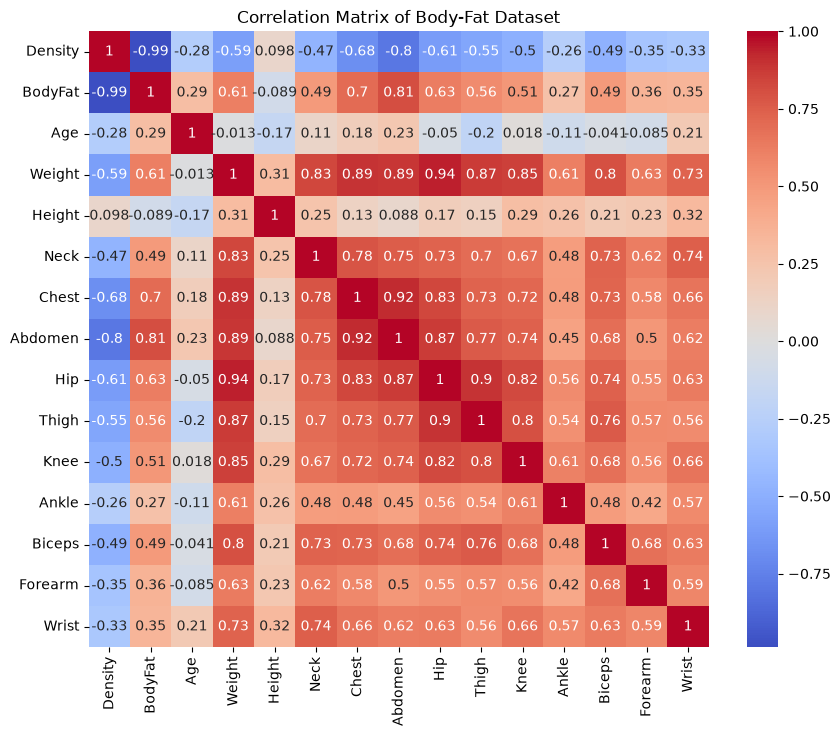

In [6]:
corr_matrix = fat.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0)
plt.title('Correlation Matrix of Body-Fat Dataset')
plt.show()

In [7]:
fat.isnull().sum()

Density    0
BodyFat    0
Age        0
Weight     0
Height     0
Neck       0
Chest      0
Abdomen    0
Hip        0
Thigh      0
Knee       0
Ankle      0
Biceps     0
Forearm    0
Wrist      0
dtype: int64

**INITIALIZATION**

In [8]:
y = fat['BodyFat']
X = fat.drop(columns = ['BodyFat'])

 1) Standardization : turn the values into range of [-1,1] so that columns with very high values doesnt get priority from columns with low value

In [9]:
def standardize(X):
    for i in X.columns:
        X[i] = (X[i] - X[i].mean())/X[i].std()
            
    return X
    

In [10]:
X = standardize(X)
X

,Density,Age,Weight,Height,Neck,Chest,Abdomen,Hip,Thigh,Knee,Ankle,Biceps,Forearm,Wrist
0,0.800055,-1.736617,-0.839575,-0.654901,-0.737198,-0.916224,-0.682176,-0.754427,-0.077325,-0.535067,-0.709414,-0.090496,-0.625474,-1.210133
1,1.561952,-1.815970,-0.193078,0.573648,0.208949,-0.856916,-0.886199,-0.168168,-0.134468,-0.535067,0.175598,-0.586975,0.116847,-0.031879
2,-0.744758,-1.815970,-0.848082,-1.064418,-1.642207,-0.595958,-0.431783,-0.098375,0.036962,0.128337,0.529602,-1.149652,-1.714210,-1.745703
3,1.025997,-1.498561,0.198223,0.573648,-0.243556,0.115746,-0.570890,0.180797,0.132201,-0.535067,-0.178407,0.041899,0.364287,-0.031879
4,-1.133588,-1.657265,0.181210,0.300637,-1.477660,-0.418032,0.690345,0.278507,0.722682,1.496607,0.529602,-0.024299,-0.477010,-0.567449
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
247,0.947180,1.992938,-1.520098,-0.859660,-1.271976,-1.378832,-0.830556,-1.550066,-1.867818,-1.571635,-0.945417,-2.208808,-1.466770,0.289463
248,-1.680053,2.151642,0.751148,-0.108879,1.196232,0.910482,1.154035,0.641430,0.036962,0.916129,0.057596,0.968660,-0.031617,2.003287
249,-1.196642,2.151642,0.266275,-1.132671,0.373496,1.218887,1.756831,0.250590,0.170296,-0.535067,-0.945417,-0.322186,-0.724450,-0.246107
250,-0.823575,2.151642,0.402379,0.095879,0.373496,0.886758,0.810905,-0.293795,-0.648759,1.247831,-0.237408,-0.586975,0.364287,1.681945


**FITNESS EVALUATION**
 1) Model Fitting (Gradient Descend)

In [11]:
def GradientDescend(X,y, learning_rate = 0.01, n_iter = 1000):
    X = np.c_[np.ones(X.shape[0]),X]
    theta = np.zeros(X.shape[1])
    n = X.shape[0]
    for i in range(n_iter):
        h = X @ theta
        theta = theta - learning_rate * X.T @ (h - y)/n
    return theta


In [12]:
GradientDescend(X,y)

array([19.14996689, -7.19902639,  0.24322083, -0.06041829,  0.02063024,
       -0.25057738,  0.20443474,  1.28902516, -0.07156847,  0.09372987,
       -0.07492834, -0.04837253, -0.10312249,  0.20728066, -0.24024931])

2. Cost Prediction (Residual Sum Squares/RSS)

In [13]:
def RSS(X,y,theta):
    X = np.c_[np.ones(X.shape[0]), X]
    h = X @ theta
    residual_sum_squares = sum((y - h)**2)
    return residual_sum_squares

In [14]:
m = RSS(X,y,GradientDescend(X,y))
m

417.03886910885166

3. Fitness Function (AIC)

In [15]:
def Calculate_AIC(X,y,residual_sum_squares):
    n = len(y) 
    k = 2 * X.shape[1] 
    aic = k + n * np.log(residual_sum_squares/n)
    return aic

In [16]:
 Calculate_AIC(X,y,m)

np.float64(154.94508599139283)

**GENERATE PARENT POPULATION**

In [17]:
def parent_pops(X,size,y):
    papa_pops = []
    for i in range(size):
        feature_arrs = np.random.choice([True,False],size = X.shape[1]) # make a list pf true and false with as many columns as X has
        if not feature_arrs.any():
            feature_arrs[np.random.randint(0, X.shape[1])] = True # so that it doesnt give a list of false only
        papa_pops.append(X.iloc[:, np.where(feature_arrs)[0]]) # put true = 1 and false = 0 
    return papa_pops

In [18]:
test_parents = parent_pops(X,10,y)
test_parents

[      Density      Neck   Abdomen     Ankle    Biceps     Wrist
 0    0.800055 -0.737198 -0.682176 -0.709414 -0.090496 -1.210133
 1    1.561952  0.208949 -0.886199  0.175598 -0.586975 -0.031879
 2   -0.744758 -1.642207 -0.431783  0.529602 -1.149652 -1.745703
 3    1.025997 -0.243556 -0.570890 -0.178407  0.041899 -0.031879
 4   -1.133588 -1.477660  0.690345  0.529602 -0.024299 -0.567449
 ..        ...       ...       ...       ...       ...       ...
 247  0.947180 -1.271976 -0.830556 -0.945417 -2.208808  0.289463
 248 -1.680053  1.196232  1.154035  0.057596  0.968660  2.003287
 249 -1.196642  0.373496  1.756831 -0.945417 -0.322186 -0.246107
 250 -0.823575  0.373496  0.810905 -0.237408 -0.586975  1.681945
 251 -1.496146  1.155095  1.478618  0.883607  0.472181  2.860198
 
 [252 rows x 6 columns],
       Density    Height      Neck     Chest   Abdomen     Ankle    Biceps  \
 0    0.800055 -0.654901 -0.737198 -0.916224 -0.682176 -0.709414 -0.090496   
 1    1.561952  0.573648  0.208949 -0

**SELECTION**
    1.Fitness of Parents

In [19]:
def parent_score(parents,y):
    pop_score = {}
    for i,parent in enumerate(parents):
        theta1 = GradientDescend(parent,y, learning_rate = 0.01, n_iter = 1000)
        rss = RSS(parent,y,theta1)
        aic = Calculate_AIC(parent,y,rss)
        pop_score[i] = aic
    return pop_score

In [20]:
test_parent_score = parent_score(test_parents,y)
test_parent_score

{0: np.float64(147.4093933887132),
 1: np.float64(143.55222604032943),
 2: np.float64(133.74170023440573),
 3: np.float64(763.744067286518),
 4: np.float64(888.1227377488747),
 5: np.float64(961.2595919642145),
 6: np.float64(867.857897538609),
 7: np.float64(774.5067898410183),
 8: np.float64(130.70397109436584),
 9: np.float64(766.5851328632696)}

    2. Survival of Fittest

In [21]:
def fittest_parents(population,lamda,y):
    parent_scores = parent_score(population,y) 
    fittest_parent = [] 
    sorted_parents = sorted(parent_scores.items(), key = lambda x:x[1]) 
    top_lamda_parents_indices = sorted_parents[:lamda] 
    top_lamda_parents = [item[0] for item in top_lamda_parents_indices] 
    for i in top_lamda_parents: 
        fittest_parent.append(population[i]) 
    return fittest_parent

In [22]:
fittest_parents(test_parents,5,y)

[      Density       Age    Weight      Neck     Chest       Hip     Ankle  \
 0    0.800055 -1.736617 -0.839575 -0.737198 -0.916224 -0.754427 -0.709414   
 1    1.561952 -1.815970 -0.193078  0.208949 -0.856916 -0.168168  0.175598   
 2   -0.744758 -1.815970 -0.848082 -1.642207 -0.595958 -0.098375  0.529602   
 3    1.025997 -1.498561  0.198223 -0.243556  0.115746  0.180797 -0.178407   
 4   -1.133588 -1.657265  0.181210 -1.477660 -0.418032  0.278507  0.529602   
 ..        ...       ...       ...       ...       ...       ...       ...   
 247  0.947180  1.992938 -1.520098 -1.271976 -1.378832 -1.550066 -0.945417   
 248 -1.680053  2.151642  0.751148  1.196232  0.910482  0.641430  0.057596   
 249 -1.196642  2.151642  0.266275  0.373496  1.218887  0.250590 -0.945417   
 250 -0.823575  2.151642  0.402379  0.373496  0.886758 -0.293795 -0.237408   
 251 -1.496146  2.310347  0.972318  1.155095  1.373089  1.004352  0.883607   
 
        Biceps   Forearm  
 0   -0.090496 -0.625474  
 1   -0.

**CROSSOVER**

In [23]:
def uniform_crossover(X,parent1, parent2):

    parent_list1 = parent1.columns.tolist()
    # temp = 0
    
    bool_arr1 = np.zeros(X.shape[1])
    for i in parent_list1:
        bool_arr1[X.columns.get_loc(i)] = 1
        
    bool_arr2 = np.zeros(X.shape[1])
    parent_list2 = parent2.columns.tolist()
    for i in parent_list2:
        bool_arr2[X.columns.get_loc(i)] = 1  
    for i in range(len(bool_arr1)):
        if np.random.uniform() >= 0.5:
            temp = bool_arr1[i]
            bool_arr1[i] = bool_arr2[i]
            bool_arr2[i] = temp
            continue
            
    new_parent1 = X.iloc[:, np.where(bool_arr1)[0]]
    new_parent2 = X.iloc[:, np.where(bool_arr2)[0]]
    return  new_parent1, new_parent2

In [24]:
test_parent1 = fittest_parents(test_parents,5,y)[0]
test_parent2 = fittest_parents(test_parents,5,y)[1]
test_parent1

,Density,Age,Weight,Neck,Chest,Hip,Ankle,Biceps,Forearm
0,0.800055,-1.736617,-0.839575,-0.737198,-0.916224,-0.754427,-0.709414,-0.090496,-0.625474
1,1.561952,-1.815970,-0.193078,0.208949,-0.856916,-0.168168,0.175598,-0.586975,0.116847
2,-0.744758,-1.815970,-0.848082,-1.642207,-0.595958,-0.098375,0.529602,-1.149652,-1.714210
3,1.025997,-1.498561,0.198223,-0.243556,0.115746,0.180797,-0.178407,0.041899,0.364287
4,-1.133588,-1.657265,0.181210,-1.477660,-0.418032,0.278507,0.529602,-0.024299,-0.477010
...,...,...,...,...,...,...,...,...,...
247,0.947180,1.992938,-1.520098,-1.271976,-1.378832,-1.550066,-0.945417,-2.208808,-1.466770
248,-1.680053,2.151642,0.751148,1.196232,0.910482,0.641430,0.057596,0.968660,-0.031617
249,-1.196642,2.151642,0.266275,0.373496,1.218887,0.250590,-0.945417,-0.322186,-0.724450
250,-0.823575,2.151642,0.402379,0.373496,0.886758,-0.293795,-0.237408,-0.586975,0.364287


In [25]:
test_parent2

,Density,Weight,Neck,Chest,Hip,Thigh,Knee,Ankle,Biceps
0,0.800055,-0.839575,-0.737198,-0.916224,-0.754427,-0.077325,-0.535067,-0.709414,-0.090496
1,1.561952,-0.193078,0.208949,-0.856916,-0.168168,-0.134468,-0.535067,0.175598,-0.586975
2,-0.744758,-0.848082,-1.642207,-0.595958,-0.098375,0.036962,0.128337,0.529602,-1.149652
3,1.025997,0.198223,-0.243556,0.115746,0.180797,0.132201,-0.535067,-0.178407,0.041899
4,-1.133588,0.181210,-1.477660,-0.418032,0.278507,0.722682,1.496607,0.529602,-0.024299
...,...,...,...,...,...,...,...,...,...
247,0.947180,-1.520098,-1.271976,-1.378832,-1.550066,-1.867818,-1.571635,-0.945417,-2.208808
248,-1.680053,0.751148,1.196232,0.910482,0.641430,0.036962,0.916129,0.057596,0.968660
249,-1.196642,0.266275,0.373496,1.218887,0.250590,0.170296,-0.535067,-0.945417,-0.322186
250,-0.823575,0.402379,0.373496,0.886758,-0.293795,-0.648759,1.247831,-0.237408,-0.586975


In [26]:
test_offspring1,test_offspring2 = uniform_crossover(X,test_parent1,test_parent2)
test_offspring2

,Density,Age,Weight,Neck,Chest,Hip,Thigh,Knee,Ankle,Biceps,Forearm
0,0.800055,-1.736617,-0.839575,-0.737198,-0.916224,-0.754427,-0.077325,-0.535067,-0.709414,-0.090496,-0.625474
1,1.561952,-1.815970,-0.193078,0.208949,-0.856916,-0.168168,-0.134468,-0.535067,0.175598,-0.586975,0.116847
2,-0.744758,-1.815970,-0.848082,-1.642207,-0.595958,-0.098375,0.036962,0.128337,0.529602,-1.149652,-1.714210
3,1.025997,-1.498561,0.198223,-0.243556,0.115746,0.180797,0.132201,-0.535067,-0.178407,0.041899,0.364287
4,-1.133588,-1.657265,0.181210,-1.477660,-0.418032,0.278507,0.722682,1.496607,0.529602,-0.024299,-0.477010
...,...,...,...,...,...,...,...,...,...,...,...
247,0.947180,1.992938,-1.520098,-1.271976,-1.378832,-1.550066,-1.867818,-1.571635,-0.945417,-2.208808,-1.466770
248,-1.680053,2.151642,0.751148,1.196232,0.910482,0.641430,0.036962,0.916129,0.057596,0.968660,-0.031617
249,-1.196642,2.151642,0.266275,0.373496,1.218887,0.250590,0.170296,-0.535067,-0.945417,-0.322186,-0.724450
250,-0.823575,2.151642,0.402379,0.373496,0.886758,-0.293795,-0.648759,1.247831,-0.237408,-0.586975,0.364287


**MUTATION**

In [27]:
def rbf_mutation(X,parent1, parent2,mutation_rate):
    # X = data.drop(target_variable, axis = 1)
    
    bool_arr1 = np.zeros(X.shape[1])
    parent_list1 = parent1.columns.tolist()
    for i in parent_list1:
        bool_arr1[X.columns.get_loc(i)] = 1
        
    bool_arr2 = np.zeros(X.shape[1])
    parent_list2 = parent2.columns.tolist()
    for i in parent_list2:
        bool_arr2[X.columns.get_loc(i)] = 1
        
    for i in range(len(bool_arr1)):
        if mutation_rate > np.random.normal(loc = .5, scale = .25, size = 1):
            bool_arr1[i] = 1-bool_arr1[i]
            continue
    for i in range(len(bool_arr2)):
        if mutation_rate > np.random.normal(loc = .5, scale = .25, size = 1):
            bool_arr2[i] = 1-bool_arr2[i]
            continue
            
    new_parent1 = X.iloc[:, np.where(bool_arr1)[0]]
    new_parent2 = X.iloc[:, np.where(bool_arr2)[0]]    
    
    return new_parent1, new_parent2

In [28]:
test_mutant1,test_mutant2 = rbf_mutation(X,test_parent1,test_parent2,0.6)
test_mutant1

,Abdomen,Thigh,Ankle,Forearm,Wrist
0,-0.682176,-0.077325,-0.709414,-0.625474,-1.210133
1,-0.886199,-0.134468,0.175598,0.116847,-0.031879
2,-0.431783,0.036962,0.529602,-1.714210,-1.745703
3,-0.570890,0.132201,-0.178407,0.364287,-0.031879
4,0.690345,0.722682,0.529602,-0.477010,-0.567449
...,...,...,...,...,...
247,-0.830556,-1.867818,-0.945417,-1.466770,0.289463
248,1.154035,0.036962,0.057596,-0.031617,2.003287
249,1.756831,0.170296,-0.945417,-0.724450,-0.246107
250,0.810905,-0.648759,-0.237408,0.364287,1.681945


**The 
 Genetic Algorithm [Elitism]**

In [29]:
def gen_alg(X, y, pop_size, no_parents_selected, iterations, mutation_rate, num_parents_to_new_gen): 
    population = parent_pops(X, pop_size, y)
    aic_scores = []

    for z in range(iterations):
        print("iteration:", z)
        parents = fittest_parents(population, no_parents_selected, y)
        new_gen = []
        new_gen.extend(parents[:num_parents_to_new_gen])
        for i in range(len(parents)):
            for j in range(i + 1, len(parents)):
                parent1 = parents[i]
                parent2 = parents[j]
                if np.random.normal(loc = .5, scale = .25, size = 1) < 0.5:
                    offspring1, offspring2 = uniform_crossover(X, parent1, parent2)
                else:
                    offspring1, offspring2 = rbf_mutation(X, parent1, parent2, mutation_rate)
                new_gen.append(offspring1)
                new_gen.append(offspring2)
        population = new_gen
        best_parent = fittest_parents(population, 1, y)[0]
        best_rss = RSS(best_parent, y, GradientDescend(best_parent, y))
        aic_scores.append(Calculate_AIC(best_parent, y, best_rss))

    return best_parent, aic_scores

In [30]:
best_parent1, aic_scores1 = gen_alg(X, y, 50, 10, 10, 0.2, 5)
print("Selected features:", best_parent1.columns.tolist())
print("Best AIC:", aic_scores1[-1])

iteration: 0


iteration: 1


iteration: 2


iteration: 3


iteration: 4


iteration: 5


iteration: 6


iteration: 7


iteration: 8


iteration: 9


Selected features: ['Density', 'Age', 'Chest', 'Hip']
Best AIC: 121.44030760398714


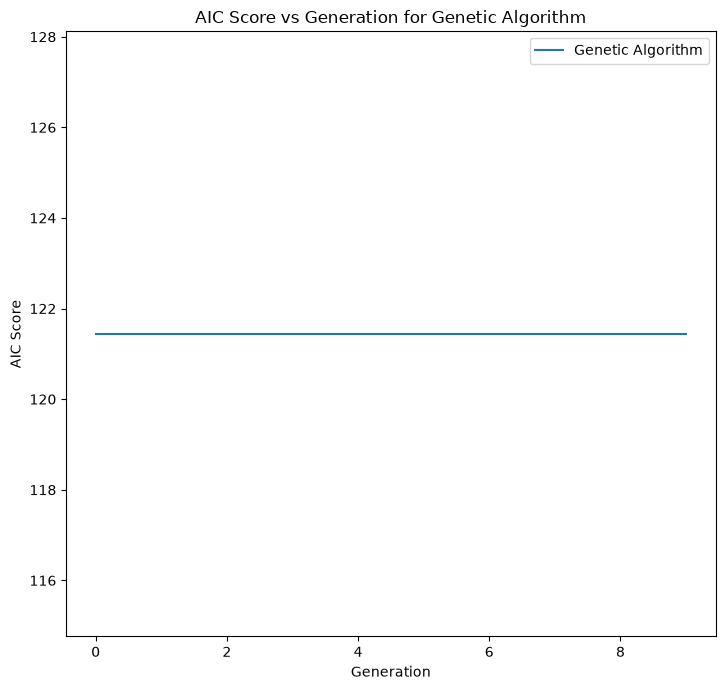

In [31]:
plt.figure(figsize=(14, 7))

plt.subplot(1, 2, 1)
plt.plot(range(len(aic_scores1)), aic_scores1, label='Genetic Algorithm')
plt.xlabel('Generation')
plt.ylabel('AIC Score')
plt.title('AIC Score vs Generation for Genetic Algorithm')
plt.legend()
plt.tight_layout()
plt.show()